In [1]:
#env_STAligner
import torch, os
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version PyTorch expects:", torch.version.cuda)
print("LD_LIBRARY_PATH:", os.environ.get("LD_LIBRARY_PATH"))

PyTorch version: 1.9.1+cu102
CUDA available: True
CUDA version PyTorch expects: 10.2
LD_LIBRARY_PATH: None


/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import anndata as ad
import scanpy as sc
import pandas as pd
import numpy as np
import scipy.sparse as sp
import scipy.linalg
import STAligner
import torch
used_device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

In [3]:
adata = sc.read_h5ad('./rep1_spot.h5ad')
print(adata)
# Get the columns of interest


AnnData object with n_obs × n_vars = 3184 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Smooth muscle cells_percentage', 'Fibroblast_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Endothelium_percentage', 'Epicardium_percentage', 'Schwan progenitors_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num'
    obsm: 'X_spatial', 'spatial'


In [4]:
used_device

device(type='cuda', index=0)

<Axes: >

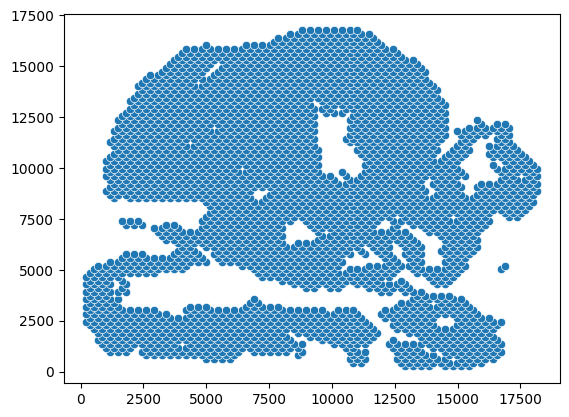

In [5]:
import seaborn as sns
sns.scatterplot(x=adata.obsm['spatial'][:,0], y=adata.obsm['spatial'][:,1], )   

In [6]:
Batch_list = []
adj_list = []
section_ids = ['rep1_spot','rep2_spot']
valis_names = ['moving_valisOutput','ref_cell_positions']
print(section_ids)
import scipy.sparse as sp

for ix, section_id in enumerate(section_ids):
    print(section_id)
    input_dir = os.path.join('./', section_id+'.h5ad')
    adata = sc.read_h5ad(input_dir)

    spatial_df = pd.read_csv(f'valis_output/{valis_names[ix]}.csv')
    spatial_df.index = spatial_df.Cell_Num.astype(str)
    try:
        adata.obs['New_X'] = spatial_df.loc[adata.obs.Cell_Num.astype(str),'Valis_X']
        adata.obs['New_Y'] = spatial_df.loc[adata.obs.Cell_Num.astype(str),'Valis_Y']
    except:
        adata.obs['New_X'] = spatial_df.loc[adata.obs.Cell_Num.astype(str),'New_X']
        adata.obs['New_Y'] = spatial_df.loc[adata.obs.Cell_Num.astype(str),'New_Y']
    adata.obsm['spatial'] = np.array([adata.obs['New_X'].values, adata.obs['New_Y'].values]).T
    adata.obsm['X_spatial'] = adata.obsm['spatial'].copy()

    adata.X = sp.csr_matrix(adata.X)
    adata.var_names_make_unique(join="++")
    cols = [
        'Smooth muscle cells_percentage',
        'Fibroblast_percentage',
        'Atrial cardiomyocytes_percentage',
        'Cardiomyocytes_percentage',
        'Endothelium_percentage',
        'Epicardium_percentage',
        'Schwan progenitors_percentage',
        'Ventricular cardiomyocytes_percentage'
    ]

    # Remove '_percentage' to get cell type names
    cell_types = [col.replace('_percentage', '') for col in cols]

    # Find the column with the maximum value for each row and assign as 'Ground Truth'
    adata.obs['Ground Truth'] = adata.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')



    # make spot name unique
    adata.obs_names = [x+'_'+section_id for x in adata.obs_names]

    # Constructing the spatial network
    STAligner.Cal_Spatial_Net(adata, rad_cutoff=150) # the spatial network are saved in adata.uns[‘adj’]
    # STAligner.Stats_Spatial_Net(adata) # plot the number of spatial neighbors

    # Normalization

    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    adj_list.append(adata.uns['adj'])
    Batch_list.append(adata)

['rep1_spot', 'rep2_spot']
rep1_spot
------Calculating spatial graph...
The graph contains 159200 edges, 3184 cells.
50.0000 neighbors per cell on average.
rep2_spot
------Calculating spatial graph...
The graph contains 190050 edges, 3801 cells.
50.0000 neighbors per cell on average.


In [7]:
adata_concat = ad.concat(Batch_list, label="slice_name", keys=section_ids)
adata_concat.obs['Ground Truth'] = adata_concat.obs['Ground Truth'].astype('category')
adata_concat.obs["batch_name"] = adata_concat.obs["slice_name"].astype('category')
print('adata_concat.shape: ', adata_concat.shape)


adata_concat.shape:  (6985, 67)


In [8]:
adj_concat = np.asarray(adj_list[0].todense())
for batch_id in range(1,len(section_ids)):
    adj_concat = scipy.linalg.block_diag(adj_concat, np.asarray(adj_list[batch_id].todense()))
adata_concat.uns['edgeList'] = np.nonzero(adj_concat)

In [9]:
%%time
adata_concat = STAligner.train_STAligner(adata_concat, verbose=True, knn_neigh = 50, device=used_device)

STAligner(
  (conv1): GATConv(67, 512, heads=1)
  (conv2): GATConv(512, 30, heads=1)
  (conv3): GATConv(30, 512, heads=1)
  (conv4): GATConv(512, 67, heads=1)
)
Pretrain with STAGATE...


100%|██████████| 500/500 [00:20<00:00, 23.82it/s]


Train with STAligner...


  0%|          | 0/500 [00:00<?, ?it/s]

Update spot triplets at epoch 500


 20%|██        | 100/500 [00:04<00:17, 23.41it/s]

... (5 outputs left out)

 80%|████████  | 400/500 [00:19<00:04, 23.39it/s]

Update spot triplets at epoch 900


100%|██████████| 500/500 [00:24<00:00, 20.40it/s]

CPU times: user 49.3 s, sys: 2.66 s, total: 52 s
Wall time: 49.1 s


In [10]:
sc.pp.neighbors(adata_concat, use_rep='STAligner', random_state=666)
sc.tl.louvain(adata_concat, random_state=666, key_added="louvain", resolution=0.2)
sc.tl.umap(adata_concat)


/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/umap/distances.py:1063: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/umap/distances.py:1071: NumbaDeprecationWarning: The 'nopython' keyword argument was not supplied to the 'numba.jit' decorator. The implicit default value for this argument is currently False, but it will be changed to True in Numba 0.59.0. See https://numba.readthedocs.io/en/stable/reference/deprecation.html#deprecation-of-object-mode-fall-back-behaviour-when-using-jit for details.
  @numba.jit()
/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8

In [11]:
adata_concat.obs.batch_name

0_rep1_spot       rep1_spot
1_rep1_spot       rep1_spot
2_rep1_spot       rep1_spot
3_rep1_spot       rep1_spot
4_rep1_spot       rep1_spot
                    ...    
3796_rep2_spot    rep2_spot
3797_rep2_spot    rep2_spot
3798_rep2_spot    rep2_spot
3799_rep2_spot    rep2_spot
3800_rep2_spot    rep2_spot
Name: batch_name, Length: 6985, dtype: category
Categories (2, object): ['rep1_spot', 'rep2_spot']

/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/scanpy/plotting/_utils.py:430: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


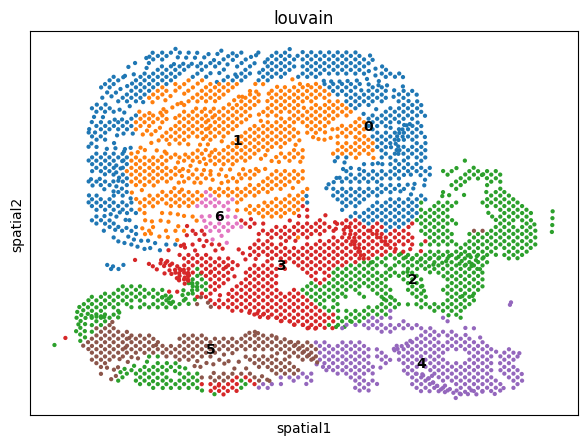

/home/adyprat/anaconda3/envs/env_STAligner/lib/python3.8/site-packages/scanpy/plotting/_utils.py:430: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list


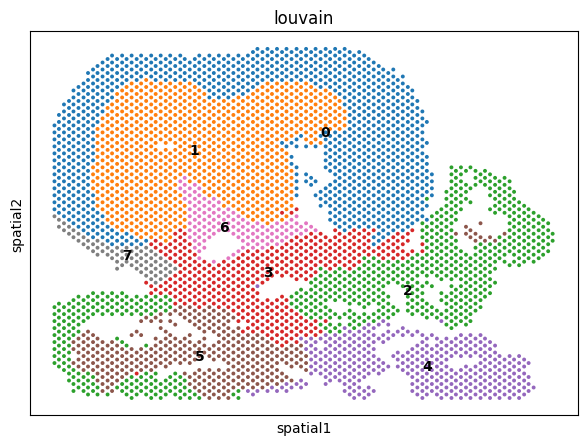

In [12]:
sc.pl.scatter(adata_concat[adata_concat.obs['batch_name']=='rep1_spot'], color='louvain', legend_loc='on data', basis='spatial')
sc.pl.scatter(adata_concat[adata_concat.obs['batch_name']=='rep2_spot'], color='louvain', legend_loc='on data', basis='spatial')


In [13]:
adata_concat

AnnData object with n_obs × n_vars = 6985 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Smooth muscle cells_percentage', 'Fibroblast_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Endothelium_percentage', 'Epicardium_percentage', 'Schwan progenitors_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'Ground Truth', 'slice_name', 'batch_name', 'louvain'
    uns: 'edgeList', 'neighbors', 'louvain', 'umap'
    obsm: 'X_spatial', 'spatial', 'STAGATE', 'STAligner', 'X_umap'
    obsp: 'distances', 'connectivities'

/mnt/e/git-workspace/STAligner/STAligner/ST_utils.py:315: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax[0].scatter(adata_slice2.obsm["spatial"][:, 0], adata_slice2.obsm["spatial"][:, 1],
/mnt/e/git-workspace/STAligner/STAligner/ST_utils.py:318: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax[1].scatter(aligned_points[:, 0], aligned_points[:, 1],


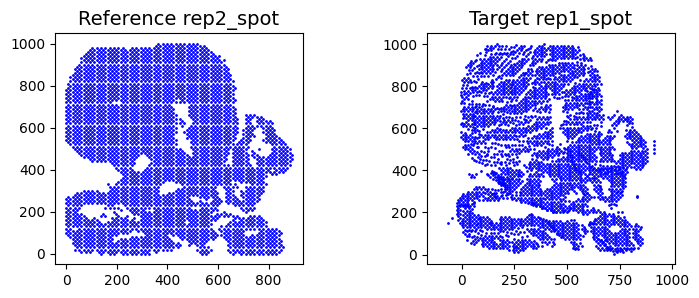

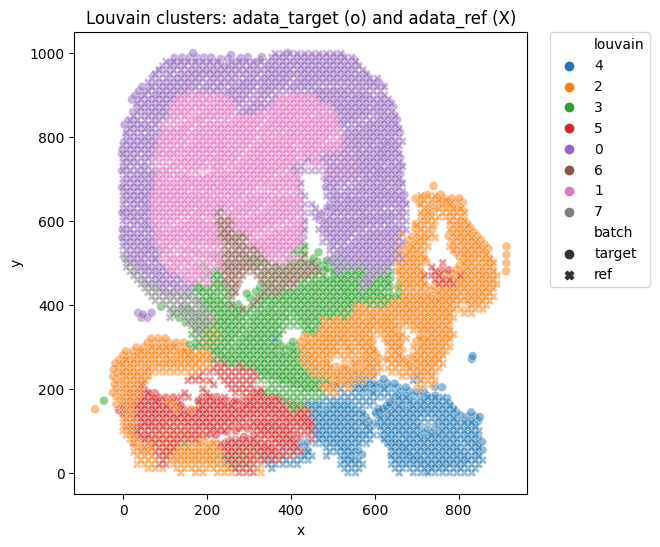

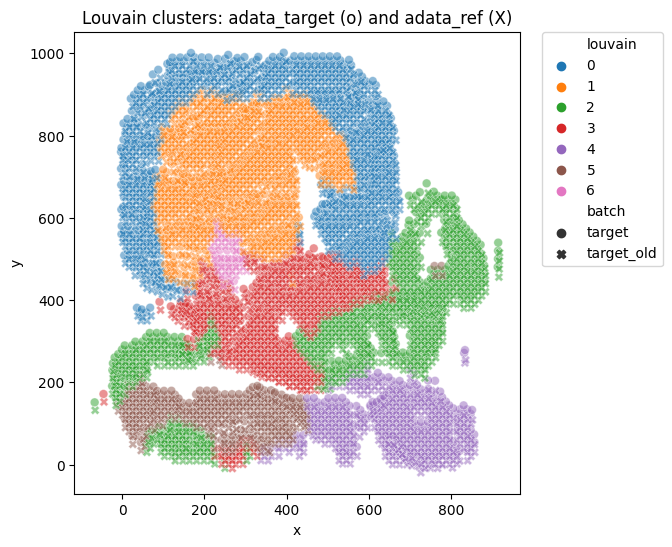

In [14]:
adata_target = adata_concat[adata_concat.obs['batch_name']=='rep1_spot'].copy()
adata_ref = adata_concat[adata_concat.obs['batch_name']=='rep2_spot'].copy()
slice_target = 'rep1_spot'
slice_ref = 'rep2_spot'
landmark_domain = ['0','1','2','3','4','5','6']
aligned_coor = STAligner.ICP_align(adata_concat, adata_target, adata_ref, slice_target, slice_ref, landmark_domain, plot_align=True)
adata_target.obsm["X_spatial"] = aligned_coor


import seaborn as sns
import matplotlib.pyplot as plt

# Prepare data for both adata_target and adata_ref
df_target = adata_target.obs.copy()
df_target['x'] = adata_target.obsm['X_spatial'][:, 0]
df_target['y'] = adata_target.obsm['X_spatial'][:, 1]
df_target['batch'] = 'target'

df_ref = adata_ref.obs.copy()
df_ref['x'] = adata_ref.obsm['spatial'][:, 0]
df_ref['y'] = adata_ref.obsm['spatial'][:, 1]
df_ref['batch'] = 'ref'

# Concatenate dataframes
df_all = pd.concat([df_target, df_ref], axis=0)

# Plot both in the same plot, using marker style for batch and color for louvain
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_all,
    x='x', y='y',
    hue='louvain',
    style='batch',
    palette='tab10',
    s=40,
    alpha=0.5
)
plt.title('Louvain clusters: adata_target (o) and adata_ref (X)')
plt.gca().set_aspect('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()




# Prepare data for both adata_target and adata_ref
df_target = adata_target.obs.copy()
df_target['x'] = adata_target.obsm['X_spatial'][:, 0]
df_target['y'] = adata_target.obsm['X_spatial'][:, 1]
df_target['batch'] = 'target'

df_ref = adata_target.obs.copy()
df_ref['x'] = adata_target.obs['New_X'].values
df_ref['y'] = adata_target.obs['New_Y'].values
df_ref['batch'] = 'target_old'

# Concatenate dataframes
df_all = pd.concat([df_target, df_ref], axis=0)

# Plot both in the same plot, using marker style for batch and color for louvain
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_all,
    x='x', y='y',
    hue='louvain',
    style='batch',
    palette='tab10',
    s=40,
    alpha=0.5
)
plt.title('Louvain clusters: adata_target (o) and adata_ref (X)')
plt.gca().set_aspect('equal')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.show()




In [19]:
adata_target.obsm['X_spatial']

array([[657.08758677,  23.10125414],
       [673.97870838,  23.06347899],
       [691.95162055,  23.04809852],
       ...,
       [487.46954206, 992.40849332],
       [504.51940809, 992.3919894 ],
       [522.47573347, 992.33277293]])

In [15]:
adata_target.obs[['New_X','New_Y']]

,New_X,New_Y
0_rep1_spot,657.516956,-0.133918
1_rep1_spot,674.407621,-0.263716
2_rep1_spot,692.380183,-0.377012
3_rep1_spot,704.671579,-2.997449
4_rep1_spot,726.064387,-19.761782
...,...,...
3179_rep1_spot,458.896835,969.977380
3180_rep1_spot,476.132349,970.059007
3181_rep1_spot,493.182212,970.083014
3182_rep1_spot,510.231735,969.973623


In [ ]:
#error due to edgeList
adata_target.uns['edgeList'] = []

In [26]:
adata_ref.uns['edgeList'] = []

In [27]:
adata_ref.obsm['X_STAligner_spatial'] = adata_ref.obsm['X_spatial'].copy()
adata_ref.write_h5ad('ref_STAligner.h5ad')

In [23]:
adata_target.obsm['X_STAligner_spatial'] = adata_target.obsm['X_spatial'].copy()
adata_target.write_h5ad('query_STAligner.h5ad')



In [29]:
# Compute nearest neighbor cell type match between adata_ref and adata_target

# Get coordinates from adata_ref and adata_target
ref_coords = adata_ref.obsm['spatial']
query_coords = adata_target.obsm['X_spatial']

# Get cell types (assuming 'CellType' exists in .obs)
ref_celltypes = adata_ref.obs['Ground Truth'].values
query_celltypes = adata_target.obs['Ground Truth'].values

# Find nearest reference cell for each query cell
from scipy.spatial import cKDTree
tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Print summary
print(f"Number of matches: {matches.sum()} / {len(matches)}")
print(f"Match percentage: {matches.mean()*100:.2f}%")

# Annotate adata_target with nearest ref cell type and match status
adata_target.obs['NearestRefCellType'] = ref_celltypes[idxs]
adata_target.obs['CellTypeMatch'] = matches


Number of matches: 1761 / 3184
Match percentage: 55.31%


In [30]:
# Compute nearest neighbor cell type match between adata_ref and adata_target

# Get coordinates from adata_ref and adata_target
ref_coords = adata_ref.obsm['spatial']
query_coords = adata_target.obs[['New_X','New_Y']].values

# Get cell types (assuming 'CellType' exists in .obs)
ref_celltypes = adata_ref.obs['Ground Truth'].values
query_celltypes = adata_target.obs['Ground Truth'].values

# Find nearest reference cell for each query cell
from scipy.spatial import cKDTree
tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Print summary
print(f"Number of matches: {matches.sum()} / {len(matches)}")
print(f"Match percentage: {matches.mean()*100:.2f}%")

# Annotate adata_target with nearest ref cell type and match status
adata_target.obs['NearestRefCellType'] = ref_celltypes[idxs]
adata_target.obs['CellTypeMatch'] = matches


Number of matches: 1834 / 3184
Match percentage: 57.60%


In [34]:
adata_ref.X

<3801x67 sparse matrix of type '<class 'numpy.float32'>'
	with 104002 stored elements in Compressed Sparse Row format>

In [36]:
adata_ref.obs['CellType'] = adata_ref.obs['Ground Truth'].astype('category')
adata_ref.X = adata_ref.X.toarray()
adata_ref.write_h5ad('ref_STAligner.h5ad')

adata_target.obs['CellType'] = adata_target.obs['Ground Truth'].astype('category')
adata_target.X = adata_target.X.toarray()
adata_target.write_h5ad('query_STAligner.h5ad')






AttributeError: 'numpy.ndarray' object has no attribute 'toarray'